### importing libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import plotly.io as pio


### getting data

In [2]:
orders = pd.read_csv('../dataset/olist_orders_dataset.csv')
order_items = pd.read_csv('../dataset/olist_order_items_dataset.csv')
customers = pd.read_csv('../dataset/olist_customers_dataset.csv')
sellers = pd.read_csv('../dataset/olist_sellers_dataset.csv')
products = pd.read_csv('../dataset/olist_products_dataset.csv')
reviews = pd.read_csv('../dataset/olist_order_reviews_dataset.csv')
category_translation = pd.read_csv('../dataset/product_category_name_translation.csv')

### processing all date time columns

In [3]:
orders['order_purchase_timestamp'] = pd.to_datetime(orders['order_purchase_timestamp'])
orders['order_delivered_carrier_date'] = pd.to_datetime(orders['order_delivered_carrier_date'])
orders['order_delivered_customer_date'] = pd.to_datetime(orders['order_delivered_customer_date'])
orders['order_estimated_delivery_date'] = pd.to_datetime(orders['order_estimated_delivery_date'])

In [4]:
### delivey time vs Review Score

In [5]:
order_reviews=orders.merge(reviews[['order_id','review_score']],on='order_id',how='inner')
order_reviews['transit_days']=(order_reviews['order_delivered_customer_date'] - order_reviews['order_purchase_timestamp']).dt.days
avg_transit=order_reviews.groupby('review_score')['transit_days'].mean().reset_index()

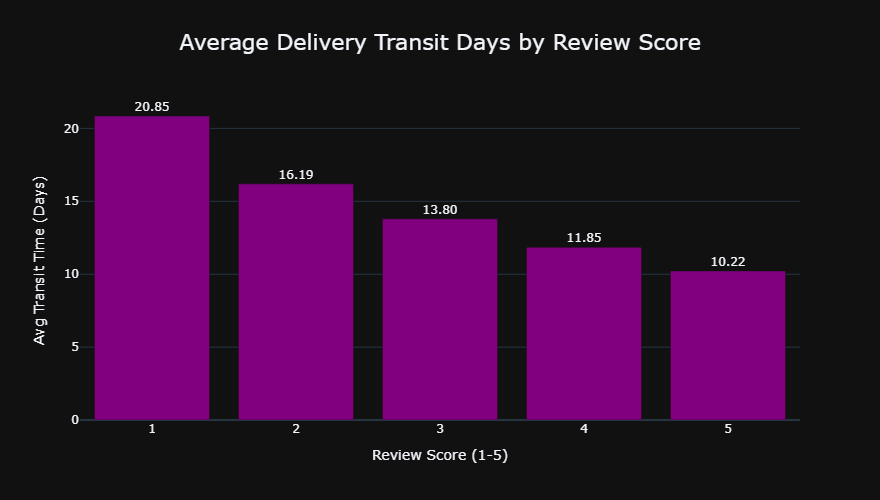

In [6]:
fig1=px.bar(data_frame=avg_transit,x='review_score',y='transit_days',title='Average Delivery Transit Days by Review Score',
           labels={'review_score': 'Review Score (1-5)','transit_days': 'Avg Transit Time (Days)'}, text='transit_days',template='plotly_dark')
fig1.update_traces(texttemplate='%{text:.2f}',textposition='outside',marker_color='purple')
fig1.update_layout(width=800,height=500,title_x=0.5,title_font=dict(size=22))
fig1.show()

In [7]:
### On-Time vs. Delayed Deliveries by Review Score

In [8]:
order_reviews['delay_days'] = (order_reviews['order_delivered_customer_date'] - order_reviews['order_estimated_delivery_date']).dt.days
order_reviews['is_delayed'] = order_reviews['delay_days'] > 0
delay_impact = order_reviews.groupby(['is_delayed'])['review_score'].mean().reset_index()
delay_impact

,is_delayed,review_score
0,False,4.211789
1,True,2.271139


In [9]:
delay_impact['Status'] = delay_impact['is_delayed'].map({True: 'Late Delivery', False: 'On-Time / Early'})
delay_impact

,is_delayed,review_score,Status
0,False,4.211789,On-Time / Early
1,True,2.271139,Late Delivery


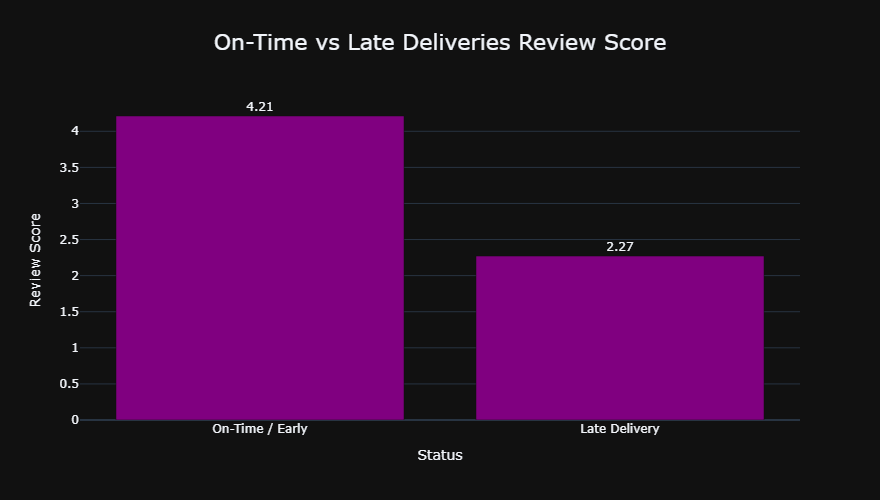

In [10]:
fig2 = px.bar(
    delay_impact, 
    x='Status', 
    y='review_score',
    title='On-Time vs Late Deliveries Review Score',
    labels={'review_score': 'Review Score', 'order_id': 'Order Count'},
    color_discrete_map={'Late Delivery': '#d9534f', 'On-Time / Early': '#2b5c6f'},
    template='plotly_dark',
    text='review_score'
)
fig2.update_traces(texttemplate='%{text:.2f}',textposition='outside',marker_color='purple')
fig2.update_layout(width=800,height=500,title_x=0.5,title_font=dict(size=22))
fig2.show()

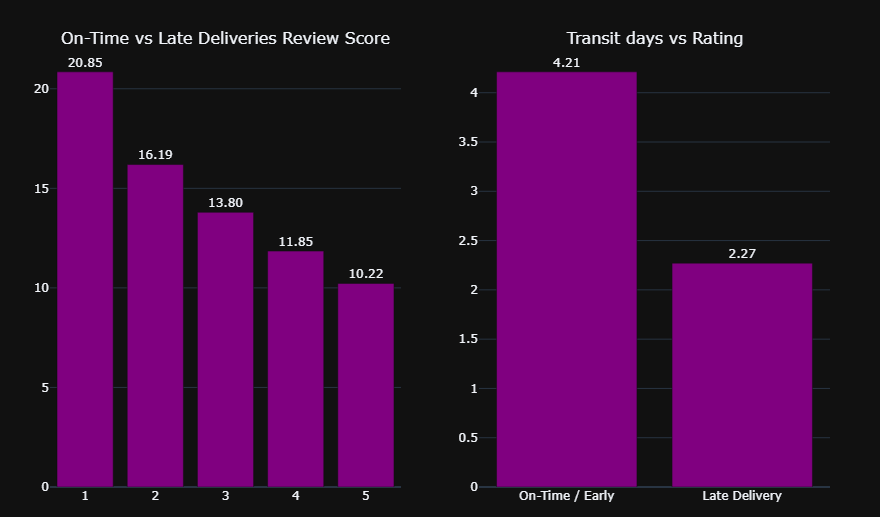

In [12]:
fig = make_subplots(rows=1, cols=2,vertical_spacing=0.2,horizontal_spacing=0.1,
                    subplot_titles=('On-Time vs Late Deliveries Review Score','Transit days vs Rating') )
for trace in fig1.data:
    fig.add_trace(trace, row=1, col=1)
for trace in fig2.data:
    fig.add_trace(trace, row=1, col=2)

fig.update_layout(height=500, width=1200,title_x=0.5,margin=dict(l=50, r=50, t=50, b=30))
fig.update_layout(grid=dict(columns=2, rows=1, pattern="independent"))
fig.update_layout(template="plotly_dark")
fig.show()

pio.write_json(fig, "transit_vs_rating.json")


In [60]:
### rfm visulization

In [13]:
monetary_df = orders.merge(customers[['customer_id','customer_unique_id']],on='customer_id')
monetary_df=monetary_df.merge(order_items[['order_id','price']], on='order_id')

In [14]:
monetary_df.head(2)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,price
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,29.99
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,af07308b275d755c9edb36a90c618231,118.70


In [15]:
mdf=monetary_df.groupby('customer_unique_id')['price'].sum().reset_index()
mdf

,customer_unique_id,price
0,0000366f3b9a7992bf8c76cfdf3221e2,129.90
1,0000b849f77a49e4a4ce2b2a4ca5be3f,18.90
2,0000f46a3911fa3c0805444483337064,69.00
3,0000f6ccb0745a6a4b88665a16c9f078,25.99
4,0004aac84e0df4da2b147fca70cf8255,180.00
...,...,...
95415,fffcf5a5ff07b0908bd4e2dbc735a684,1570.00
95416,fffea47cd6d3cc0a88bd621562a9d061,64.89
95417,ffff371b4d645b6ecea244b27531430a,89.90
95418,ffff5962728ec6157033ef9805bacc48,115.00


In [16]:
o_cust = orders.merge(customers[['customer_id','customer_unique_id']],on='customer_id')
max_date = o_cust['order_purchase_timestamp'].max()
rfm= o_cust.groupby('customer_unique_id').agg(
    Recency=('order_purchase_timestamp', lambda x: (max_date - x.max()).days),
    Frequency=('order_id', 'nunique')
).reset_index().sort_values(by='Frequency',ascending=False)

In [17]:
rfm

,customer_unique_id,Recency,Frequency
52973,8d50f5eadf50201ccdcedfb9e2ac8455,57,17
23472,3e43e6105506432c953e165fb2acf44c,231,9
37797,6469f99c1f9dfae7733b25662e7f1782,111,7
76082,ca77025e7201e3b30c44b472ff346268,138,7
10354,1b6c7548a2a1f9037c1fd3ddfed95f33,245,7
...,...,...,...
32508,5657dfebff5868c4dc7e8355fea865c4,340,1
32507,5657596addb4d7b07b32cd330614bdf8,348,1
32506,5656eb169546146caeab56c3ffc3d268,83,1
32505,5656a8fabc8629ff96b2bc14f8c09a27,321,1


In [18]:
rfm=rfm.merge(mdf,on='customer_unique_id')
rfm

,customer_unique_id,Recency,Frequency,price
0,8d50f5eadf50201ccdcedfb9e2ac8455,57,17,729.62
1,3e43e6105506432c953e165fb2acf44c,231,9,1000.85
2,6469f99c1f9dfae7733b25662e7f1782,111,7,664.20
3,ca77025e7201e3b30c44b472ff346268,138,7,806.61
4,1b6c7548a2a1f9037c1fd3ddfed95f33,245,7,809.21
...,...,...,...,...
95415,5657dfebff5868c4dc7e8355fea865c4,340,1,89.99
95416,5657596addb4d7b07b32cd330614bdf8,348,1,159.99
95417,5656eb169546146caeab56c3ffc3d268,83,1,110.00
95418,5656a8fabc8629ff96b2bc14f8c09a27,321,1,14.03


In [19]:
rfm.columns=['customer_unique_id','Recency','Frequency','Monetary']
rfm.head()

,customer_unique_id,Recency,Frequency,Monetary
0,8d50f5eadf50201ccdcedfb9e2ac8455,57,17,729.62
1,3e43e6105506432c953e165fb2acf44c,231,9,1000.85
2,6469f99c1f9dfae7733b25662e7f1782,111,7,664.20
3,ca77025e7201e3b30c44b472ff346268,138,7,806.61
4,1b6c7548a2a1f9037c1fd3ddfed95f33,245,7,809.21


In [20]:
def assign_rfm(row):
    if row['Frequency'] > 1 and row['Monetary'] >= 200: return 'Champions'
    elif row['Frequency'] > 1 and row['Recency'] <= 180: return 'Loyal Customers'
    elif row['Frequency'] > 1 and row['Recency'] > 180: return 'At-Risk Tiers'
    elif row['Frequency'] == 1 and row['Recency'] <= 90: return 'Recent One-Time Buyers'
    elif row['Frequency'] == 1 and row['Recency'] > 180: return 'Hibernating Testers'
    else: return 'Standard Core Customers'

In [21]:
rfm['RFM_Segment']=rfm.apply(assign_rfm,axis=1)
rfm

,customer_unique_id,Recency,Frequency,Monetary,RFM_Segment
0,8d50f5eadf50201ccdcedfb9e2ac8455,57,17,729.62,Champions
1,3e43e6105506432c953e165fb2acf44c,231,9,1000.85,Champions
2,6469f99c1f9dfae7733b25662e7f1782,111,7,664.20,Champions
3,ca77025e7201e3b30c44b472ff346268,138,7,806.61,Champions
4,1b6c7548a2a1f9037c1fd3ddfed95f33,245,7,809.21,Champions
...,...,...,...,...,...
95415,5657dfebff5868c4dc7e8355fea865c4,340,1,89.99,Hibernating Testers
95416,5657596addb4d7b07b32cd330614bdf8,348,1,159.99,Hibernating Testers
95417,5656eb169546146caeab56c3ffc3d268,83,1,110.00,Recent One-Time Buyers
95418,5656a8fabc8629ff96b2bc14f8c09a27,321,1,14.03,Hibernating Testers


In [22]:
rfm_count=rfm.groupby('RFM_Segment').agg(
    Customer_count=('customer_unique_id','count'),
    Revenue=('Monetary','sum')
).reset_index()

In [23]:
rfm_count

,RFM_Segment,Customer_count,Revenue
0,At-Risk Tiers,1150,133940.50
1,Champions,1324,584358.64
2,Hibernating Testers,65510,9025555.96
3,Loyal Customers,515,60522.83
4,Recent One-Time Buyers,9263,1258103.15
5,Standard Core Customers,17658,2529162.62


In [24]:
fig3 = px.treemap(
    rfm_count, 
    path=['RFM_Segment'],
    values='Revenue',
    color='Revenue',
    color_continuous_scale='pubu',
    title='RFM Customer Segment Headcount & Revenue Contribution',
    hover_data={'Customer_count': True, 'Revenue': True},
    labels='Cust: ' + rfm_count['Customer_count'].astype(str) + 
         'Rev: ' + rfm_count['Revenue'].astype(str)
)

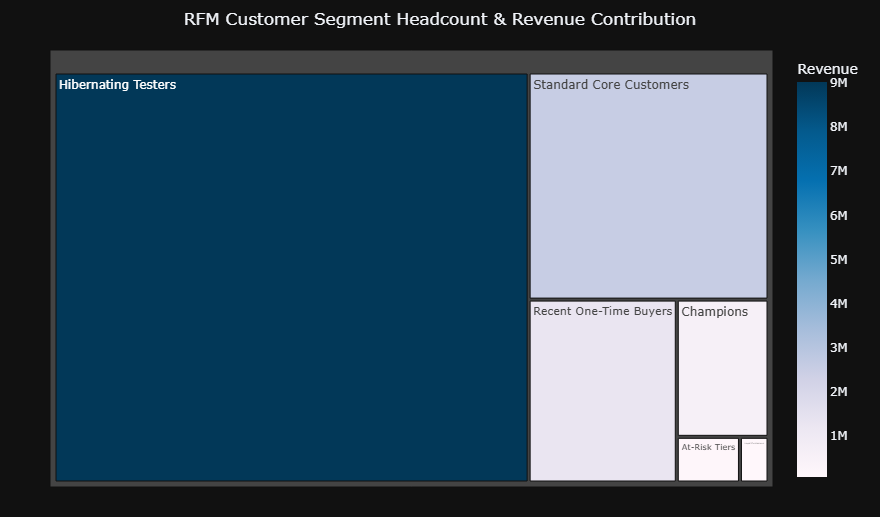

In [26]:
fig3.update_layout(height=500, width=1200,title_x=0.5,margin=dict(l=50, r=50, t=50, b=30))
fig3.update_layout(template="plotly_dark")
fig3.show()
pio.write_json(fig3, "RFM.json")

In [54]:
## ABC analysis

In [28]:
df_prod = order_items.merge(products[['product_id', 'product_category_name']], on='product_id')
df_prod=df_prod.merge(category_translation, on='product_category_name', how='left')


In [29]:
df_prod.head(2)

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_category_name,product_category_name_english
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.9,13.29,cool_stuff,cool_stuff
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.9,19.93,pet_shop,pet_shop


In [30]:
df_prod.isnull().sum()

order_id                            0
order_item_id                       0
product_id                          0
seller_id                           0
shipping_limit_date                 0
price                               0
freight_value                       0
product_category_name            1603
product_category_name_english    1627
dtype: int64

In [31]:
df_prod['category'] = df_prod['product_category_name_english'].fillna('Unknown')

In [32]:
abc=df_prod.groupby('category')['price'].sum().reset_index().sort_values(by='price', ascending=False)
abc

,category,price
44,health_beauty,1258681.34
71,watches_gifts,1205005.68
8,bed_bath_table,1036988.68
66,sports_leisure,988048.97
16,computers_accessories,911954.32
...,...,...
36,flowers,1110.04
47,home_comfort_2,760.27
12,cds_dvds_musicals,730.00
30,fashion_childrens_clothes,569.85


In [33]:
abc['cumulative_share']=abc['price'].cumsum()/abc['price'].sum()
abc

,category,price,cumulative_share
44,health_beauty,1258681.34,0.092607
71,watches_gifts,1205005.68,0.181265
8,bed_bath_table,1036988.68,0.257561
66,sports_leisure,988048.97,0.330256
16,computers_accessories,911954.32,0.397353
...,...,...,...
36,flowers,1110.04,0.999828
47,home_comfort_2,760.27,0.999884
12,cds_dvds_musicals,730.00,0.999937
30,fashion_childrens_clothes,569.85,0.999979


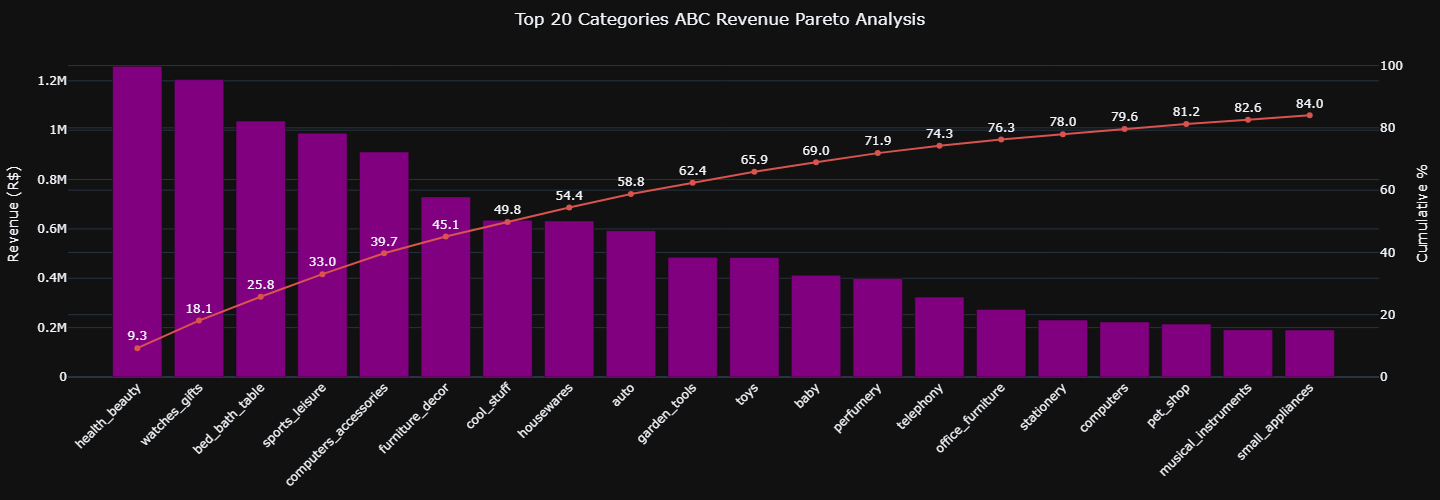

In [34]:
fig4=go.Figure()
fig4.add_trace(go.Bar(x=abc['category'].head(20),y=abc['price'].head(20),name="Category Revenue",marker_color="purple"))
fig4.add_trace(go.Scatter(x=abc['category'].head(20),y=abc['cumulative_share'].head(20)*100,name="Cumulative %",yaxis="y2",line=dict(color="#d9534f", width=2),mode="lines+markers+text",
    text=(abc['cumulative_share'].head(20) * 100).round(1).astype(str),
    textposition="top center", ))

fig4.update_layout(title="Top 20 Categories ABC Revenue Pareto Analysis",yaxis=dict(title="Revenue (R$)"),yaxis2=dict(title="Cumulative %", overlaying="y", side="right", range=[0, 105]),
    xaxis=dict(tickangle=-45),template='plotly_dark',showlegend=False)
fig4.update_layout(height=500, width=1200,title_x=0.5,margin=dict(l=50, r=50, t=50, b=30))
fig4.show()
pio.write_json(fig4, "ABC.json")

In [35]:
### xyz analysis

In [36]:
df_prod_time = df_prod.merge(orders[['order_id', 'order_purchase_timestamp']], on='order_id')
df_prod_time['year_month'] = df_prod_time['order_purchase_timestamp'].dt.to_period('M')

In [37]:
monthly_demand = df_prod_time.groupby(['category', 'year_month'])['order_item_id'].count().reset_index()
monthly_demand

,category,year_month,order_item_id
0,Unknown,2016-10,2
1,Unknown,2017-01,13
2,Unknown,2017-02,58
3,Unknown,2017-03,63
4,Unknown,2017-04,73
...,...,...,...
1269,watches_gifts,2018-04,505
1270,watches_gifts,2018-05,636
1271,watches_gifts,2018-06,481
1272,watches_gifts,2018-07,528


In [38]:
xyz=monthly_demand.groupby('category')['order_item_id'].agg(['mean','std']).reset_index()
xyz

,category,mean,std
0,Unknown,77.476190,48.067264
1,agro_industry_and_commerce,11.157895,9.494227
2,air_conditioning,14.142857,6.843140
3,art,11.611111,10.617072
4,arts_and_craftmanship,4.000000,4.690416
...,...,...,...
67,stationery,125.850000,91.044393
68,tablets_printing_image,4.882353,3.551098
69,telephony,206.590909,111.308948
70,toys,196.047619,114.940191


In [39]:
xyz['cv']=(xyz['std']/xyz['mean']).fillna(0)
xyz

,category,mean,std,cv
0,Unknown,77.476190,48.067264,0.620413
1,agro_industry_and_commerce,11.157895,9.494227,0.850898
2,air_conditioning,14.142857,6.843140,0.483858
3,art,11.611111,10.617072,0.914389
4,arts_and_craftmanship,4.000000,4.690416,1.172604
...,...,...,...,...
67,stationery,125.850000,91.044393,0.723436
68,tablets_printing_image,4.882353,3.551098,0.727333
69,telephony,206.590909,111.308948,0.538789
70,toys,196.047619,114.940191,0.586287


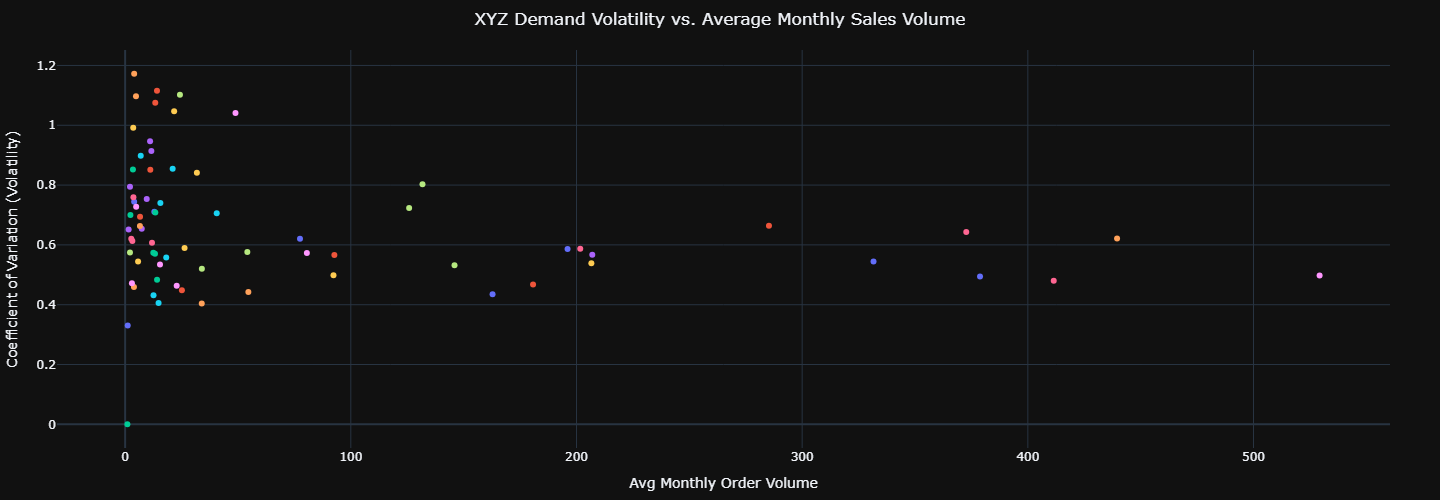

In [41]:
fig5 = px.scatter(xyz,x='mean',y='cv',hover_name='category',color='category',
    title='XYZ Demand Volatility vs. Average Monthly Sales Volume',
    labels={'mean': 'Avg Monthly Order Volume', 'cv': 'Coefficient of Variation (Volatility)'},
    template='plotly_dark'
)
fig5.update_layout(height=500, width=1200,title_x=0.5,margin=dict(l=50, r=50, t=50, b=30),showlegend=False)
fig5.show()
pio.write_json(fig5, "XYZ.json")

In [42]:
### Seller Risk Matrix

In [43]:
seller_df = order_items.merge(orders[['order_id', 'order_status', 'order_purchase_timestamp', 'order_delivered_carrier_date']], on='order_id')
seller_df

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,order_status,order_purchase_timestamp,order_delivered_carrier_date
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,delivered,2017-09-13 08:59:02,2017-09-19 18:34:16
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,delivered,2017-04-26 10:53:06,2017-05-04 14:35:00
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,delivered,2018-01-14 14:33:31,2018-01-16 12:36:48
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,delivered,2018-08-08 10:00:35,2018-08-10 13:28:00
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,delivered,2017-02-04 13:57:51,2017-02-16 09:46:09
...,...,...,...,...,...,...,...,...,...,...
112645,fffc94f6ce00a00581880bf54a75a037,1,4aa6014eceb682077f9dc4bffebc05b0,b8bc237ba3788b23da09c0f1f3a3288c,2018-05-02 04:11:01,299.99,43.41,delivered,2018-04-23 13:57:06,2018-04-25 12:09:00
112646,fffcd46ef2263f404302a634eb57f7eb,1,32e07fd915822b0765e448c4dd74c828,f3c38ab652836d21de61fb8314b69182,2018-07-20 04:31:48,350.00,36.53,delivered,2018-07-14 10:26:46,2018-07-17 08:05:00
112647,fffce4705a9662cd70adb13d4a31832d,1,72a30483855e2eafc67aee5dc2560482,c3cfdc648177fdbbbb35635a37472c53,2017-10-30 17:14:25,99.90,16.95,delivered,2017-10-23 17:07:56,2017-10-26 15:13:14
112648,fffe18544ffabc95dfada21779c9644f,1,9c422a519119dcad7575db5af1ba540e,2b3e4a2a3ea8e01938cabda2a3e5cc79,2017-08-21 00:04:32,55.99,8.72,delivered,2017-08-14 23:02:59,2017-08-15 19:02:53


In [44]:
seller_df['handover_time']=(seller_df['order_delivered_carrier_date']-seller_df['order_purchase_timestamp']).dt.days

In [45]:
seller_df.head(2)

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,order_status,order_purchase_timestamp,order_delivered_carrier_date,handover_time
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.9,13.29,delivered,2017-09-13 08:59:02,2017-09-19 18:34:16,6.0
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.9,19.93,delivered,2017-04-26 10:53:06,2017-05-04 14:35:00,8.0


In [46]:
seller_perf=seller_df.groupby('seller_id').agg(
    Total_orders=('order_id','nunique'),
    Canceled_orders=('order_status',lambda x: (x=='canceled').sum()),
    Avg_handover_days=('handover_time','mean'),
    Total_revenue=('price','sum')
).reset_index()
seller_perf

,seller_id,Total_orders,Canceled_orders,Avg_handover_days,Total_revenue
0,0015a82c2db000af6aaaf3ae2ecb0532,3,0,3.000000,2685.00
1,001cca7ae9ae17fb1caed9dfb1094831,200,0,2.133891,25080.03
2,001e6ad469a905060d959994f1b41e4f,1,1,NaN,250.00
3,002100f778ceb8431b7a1020ff7ab48f,51,0,4.090909,1234.50
4,003554e2dce176b5555353e4f3555ac8,1,0,0.000000,120.00
...,...,...,...,...,...
3090,ffcfefa19b08742c5d315f2791395ee5,1,1,NaN,69.90
3091,ffdd9f82b9a447f6f8d4b91554cc7dd3,18,0,3.800000,2101.20
3092,ffeee66ac5d5a62fe688b9d26f83f534,14,0,6.428571,1839.86
3093,fffd5413c0700ac820c7069d66d98c89,60,1,1.885246,9062.30


In [47]:
seller_perf['Cancel_rate'] = (seller_perf['Canceled_orders'] / seller_perf['Total_orders']) * 100
seller_perf.head()

,seller_id,Total_orders,Canceled_orders,Avg_handover_days,Total_revenue,Cancel_rate
0,0015a82c2db000af6aaaf3ae2ecb0532,3,0,3.000000,2685.00,0.0
1,001cca7ae9ae17fb1caed9dfb1094831,200,0,2.133891,25080.03,0.0
2,001e6ad469a905060d959994f1b41e4f,1,1,NaN,250.00,100.0
3,002100f778ceb8431b7a1020ff7ab48f,51,0,4.090909,1234.50,0.0
4,003554e2dce176b5555353e4f3555ac8,1,0,0.000000,120.00,0.0


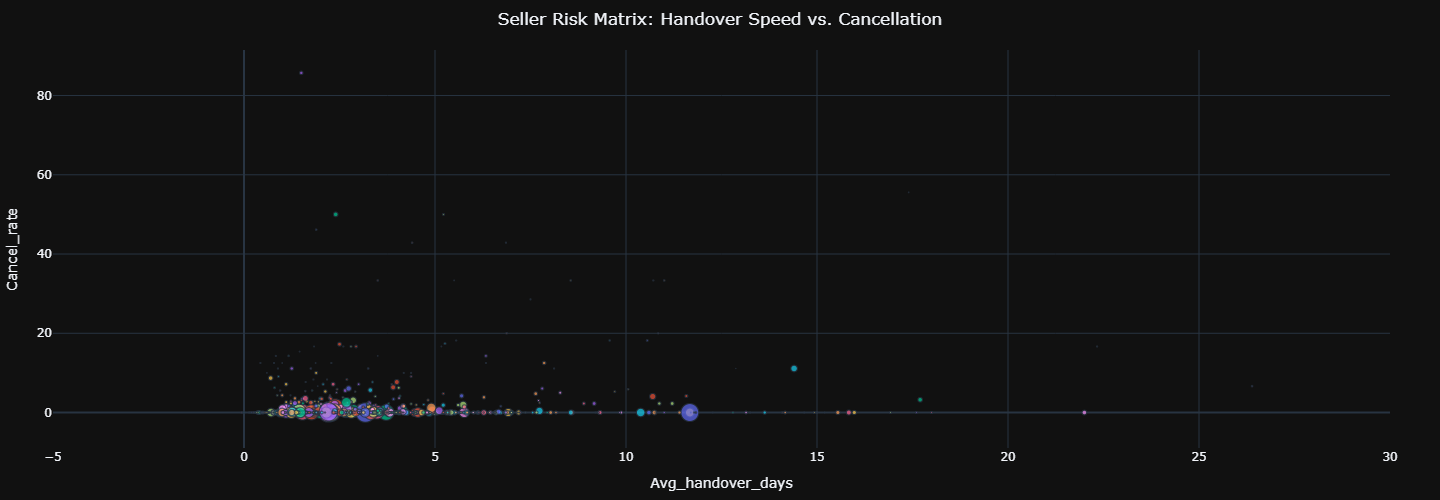

In [50]:
fig6 = px.scatter(
    seller_perf[seller_perf['Total_orders'] > 5], 
    x='Avg_handover_days', 
    y='Cancel_rate', 
    size='Total_revenue',
    color='seller_id',
    hover_name='seller_id',
    title='Seller Risk Matrix: Handover Speed vs. Cancellation',
    labels={'Avg_Handover_Days': 'Avg Handover Latency (Days)', 'Cancel_Rate': 'Cancellation Rate (%)'},
    template='plotly_dark'
)
fig6.update_layout(height=500, width=1200,title_x=0.5,margin=dict(l=50, r=50, t=50, b=30),xaxis=dict(side="right", range=[-5, 30]),showlegend=False)
fig6.show()
pio.write_json(fig6, "Seller_risk.json")

In [51]:
### State-Level Supply vs. Demand

In [52]:
cust_orders = orders.merge(customers[['customer_id', 'customer_state']], on='customer_id')
c_state = cust_orders.groupby('customer_state')['order_id'].nunique().reset_index().rename(columns={'order_id': 'Customer_Demand'})
c_state

,customer_state,Customer_Demand
0,AC,81
1,AL,413
2,AM,148
3,AP,68
4,BA,3380
5,CE,1336
6,DF,2140
7,ES,2033
8,GO,2020
9,MA,747


In [53]:
seller_orders = order_items.merge(sellers[['seller_id', 'seller_state']], on='seller_id')
s_state = seller_orders.groupby('seller_state')['order_id'].nunique().reset_index().rename(columns={'order_id': 'Seller_Supply'})
s_state

,seller_state,Seller_Supply
0,AC,1
1,AM,3
2,BA,569
3,CE,91
4,DF,824
5,ES,318
6,GO,463
7,MA,392
8,MG,7930
9,MS,49


In [54]:
geo_df = c_state.merge(s_state,left_on='customer_state',right_on='seller_state',how='outer').fillna(0)
geo_df

,customer_state,Customer_Demand,seller_state,Seller_Supply
0,AC,81,AC,1.0
1,AL,413,0,0.0
2,AM,148,AM,3.0
3,AP,68,0,0.0
4,BA,3380,BA,569.0
5,CE,1336,CE,91.0
6,DF,2140,DF,824.0
7,ES,2033,ES,318.0
8,GO,2020,GO,463.0
9,MA,747,MA,392.0


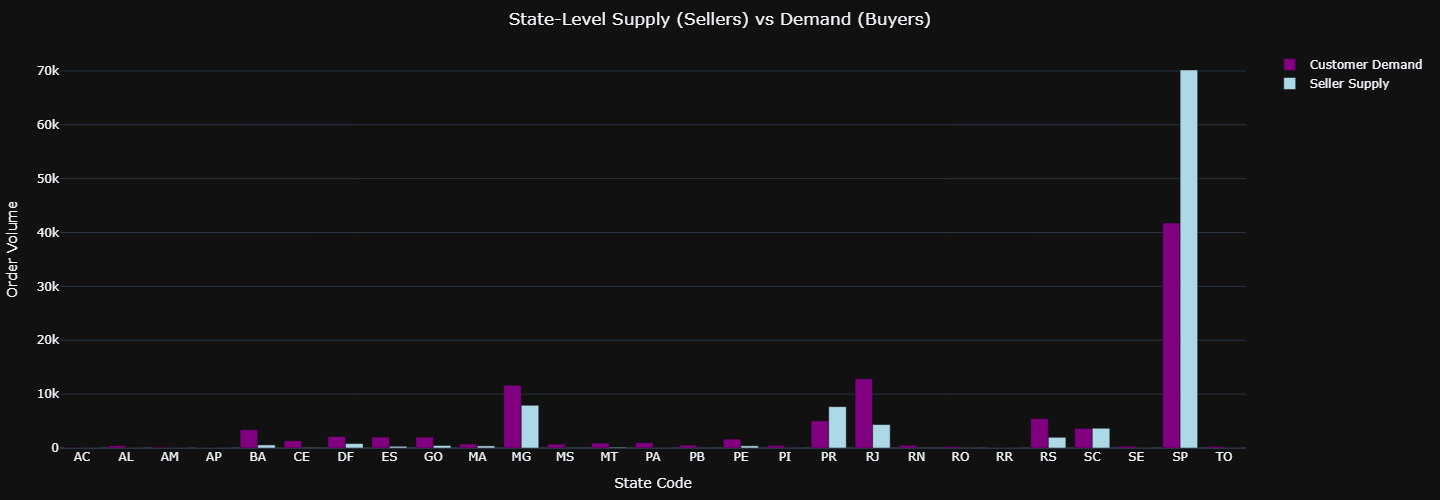

In [55]:
fig7=go.Figure()
fig7.add_trace(go.Bar(x=geo_df['customer_state'], y=geo_df['Customer_Demand'], name="Customer Demand", marker_color="purple"))
fig7.add_trace(go.Bar(x=geo_df['customer_state'], y=geo_df['Seller_Supply'], name="Seller Supply", marker_color="lightblue"))
fig7.update_layout(barmode='group',title='State-Level Supply (Sellers) vs Demand (Buyers)',xaxis_title="State Code",yaxis_title="Order Volume",template='plotly_dark')
fig7.update_layout(height=500, width=1200,title_x=0.5,margin=dict(l=50, r=50, t=50, b=30))
fig7.show()
pio.write_json(fig7, "State_Supply.json")

In [56]:
# Hourly Purchase Heatmap

In [57]:
orders['Hour'] = orders['order_purchase_timestamp'].dt.hour
orders['Day_Name'] = orders['order_purchase_timestamp'].dt.day_name()
orders.head(2)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,Hour,Day_Name
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,10,Monday
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,20,Tuesday


In [58]:
days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
hourly_pivot = orders.pivot_table(index='Day_Name', columns='Hour', values='order_id', aggfunc='nunique').reindex(days_order)
hourly_pivot

Hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
Day_Name,,,,,,,,,,,,,,,,,,,,,
Monday,328,134,66,36,21,22,69,160,479,783,...,1096,1079,1094,992,928,945,1027,1118,991,717
Tuesday,306,158,80,28,29,24,71,223,522,864,...,1124,1047,1081,967,877,924,988,1027,965,692
Wednesday,397,179,81,33,33,27,93,211,517,829,...,1050,983,1040,967,852,848,904,963,878,615
Thursday,355,167,75,39,31,28,85,220,502,758,...,977,928,1077,909,784,826,839,840,857,551
Friday,426,216,72,49,40,36,97,206,493,768,...,961,979,974,817,723,784,738,726,702,512
Saturday,315,175,67,43,25,24,53,106,249,434,...,677,722,697,701,710,756,730,654,550,429
Sunday,267,141,69,44,27,27,34,105,205,349,...,684,716,712,797,895,899,967,889,873,607


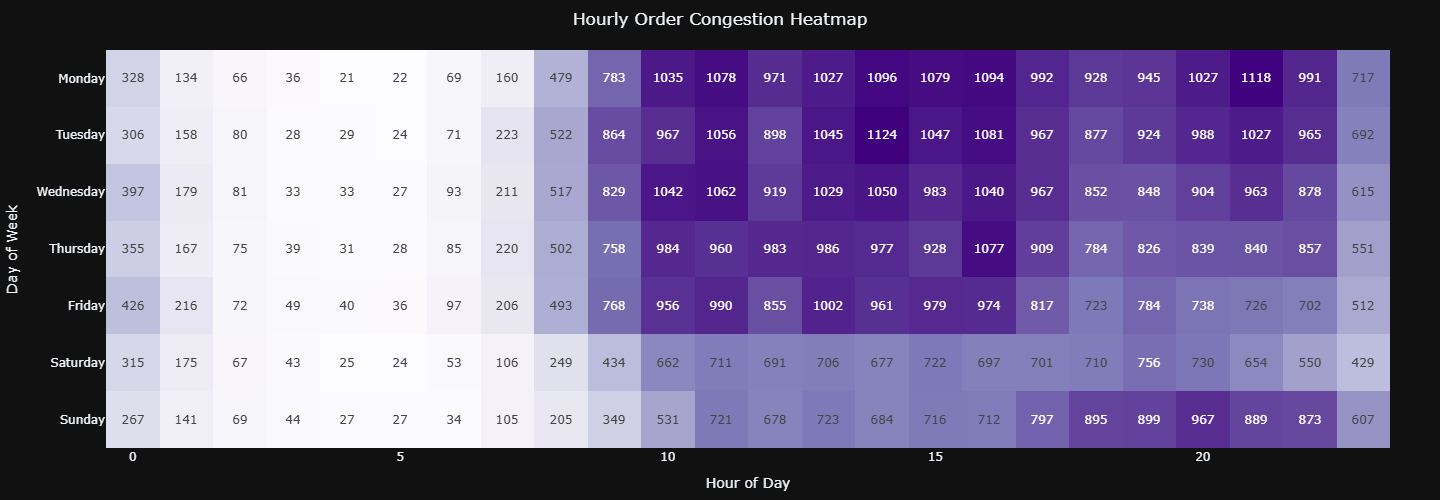

In [59]:
fig8=px.imshow(hourly_pivot,text_auto=True,color_continuous_scale='purples',title='Hourly Order Congestion Heatmap',labels=dict(x="Hour of Day", y="Day of Week", color="Orders"))
fig8.update_layout(height=500, width=1200,title_x=0.5,margin=dict(l=50, r=50, t=50, b=30),template='plotly_dark',coloraxis_showscale=False)
fig8.show()
pio.write_json(fig8, "Hourly_purchase.json")

In [60]:
# Market Basket Affinity (Top Category Pairs)

In [61]:
item_cat=order_items.merge(products[['product_id', 'product_category_name']], on='product_id')
item_cat=item_cat.merge(category_translation, on='product_category_name', how='left')
item_cat['category'] = item_cat['product_category_name_english'].fillna('Unknown')
item_cat

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_category_name,product_category_name_english,category
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,cool_stuff,cool_stuff,cool_stuff
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,pet_shop,pet_shop,pet_shop
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,moveis_decoracao,furniture_decor,furniture_decor
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,perfumaria,perfumery,perfumery
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,ferramentas_jardim,garden_tools,garden_tools
...,...,...,...,...,...,...,...,...,...,...
112645,fffc94f6ce00a00581880bf54a75a037,1,4aa6014eceb682077f9dc4bffebc05b0,b8bc237ba3788b23da09c0f1f3a3288c,2018-05-02 04:11:01,299.99,43.41,utilidades_domesticas,housewares,housewares
112646,fffcd46ef2263f404302a634eb57f7eb,1,32e07fd915822b0765e448c4dd74c828,f3c38ab652836d21de61fb8314b69182,2018-07-20 04:31:48,350.00,36.53,informatica_acessorios,computers_accessories,computers_accessories
112647,fffce4705a9662cd70adb13d4a31832d,1,72a30483855e2eafc67aee5dc2560482,c3cfdc648177fdbbbb35635a37472c53,2017-10-30 17:14:25,99.90,16.95,esporte_lazer,sports_leisure,sports_leisure
112648,fffe18544ffabc95dfada21779c9644f,1,9c422a519119dcad7575db5af1ba540e,2b3e4a2a3ea8e01938cabda2a3e5cc79,2017-08-21 00:04:32,55.99,8.72,informatica_acessorios,computers_accessories,computers_accessories


In [62]:
multi_orders = item_cat.groupby('order_id').filter(lambda x: len(x['category'].unique()) > 1)
multi_orders

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_category_name,product_category_name_english,category
80,002f98c0f7efd42638ed6100ca699b42,1,d41dc2f2979f52d75d78714b378d4068,7299e27ed73d2ad986de7f7c77d919fa,2017-08-10 09:30:15,8.99,32.57,consoles_games,consoles_games,consoles_games
81,002f98c0f7efd42638ed6100ca699b42,2,880be32f4db1d9f6e2bec38fb6ac23ab,fa40cc5b934574b62717c68f3d678b6d,2017-08-10 09:30:15,44.90,7.16,brinquedos,toys,toys
151,005d9a5423d47281ac463a968b3936fb,1,fb7a100ec8c7b34f60cec22b1a9a10e0,d98eec89afa3380e14463da2aabaea72,2017-10-24 12:28:16,49.99,18.12,brinquedos,toys,toys
152,005d9a5423d47281ac463a968b3936fb,2,4c3ae5db49258df0784827bdacf3b396,d98eec89afa3380e14463da2aabaea72,2017-10-24 12:28:16,24.99,13.58,bebes,baby,baby
153,005d9a5423d47281ac463a968b3936fb,3,4c3ae5db49258df0784827bdacf3b396,d98eec89afa3380e14463da2aabaea72,2017-10-24 12:28:16,24.99,13.58,bebes,baby,baby
...,...,...,...,...,...,...,...,...,...,...
112500,ffa5e4c604dea4f0a59d19cc2322ac19,1,59d8034bb2a82cd5092e78d42148fa44,59cd88080b93f3c18508673122d26169,2017-12-11 08:41:20,29.99,15.10,pet_shop,pet_shop,pet_shop
112501,ffa5e4c604dea4f0a59d19cc2322ac19,2,bd421826916d3e1d445cb860cea3c0fb,59cd88080b93f3c18508673122d26169,2017-12-11 08:41:20,29.99,15.10,NaN,NaN,Unknown
112530,ffb8f7de8940249a3221252818937ecb,1,bd6e8cf9fe4122c385da2bcb9f979d5d,9f50216bfd01913736a55a11b55ea842,2018-07-27 09:04:32,45.00,6.79,telefonia,telephony,telephony
112531,ffb8f7de8940249a3221252818937ecb,2,803f77475e1b51b47f1bfec4f2ec353f,c9c7905cffc4ef9ff9f113554423e671,2018-07-25 09:04:32,79.99,6.37,automotivo,auto,auto


In [63]:
pairs = multi_orders.merge(multi_orders, on='order_id')
pairs = pairs[pairs['category_x'] < pairs['category_y']]
pairs

,order_id,order_item_id_x,product_id_x,seller_id_x,shipping_limit_date_x,price_x,freight_value_x,product_category_name_x,product_category_name_english_x,category_x,order_item_id_y,product_id_y,seller_id_y,shipping_limit_date_y,price_y,freight_value_y,product_category_name_y,product_category_name_english_y,category_y
1,002f98c0f7efd42638ed6100ca699b42,1,d41dc2f2979f52d75d78714b378d4068,7299e27ed73d2ad986de7f7c77d919fa,2017-08-10 09:30:15,8.99,32.57,consoles_games,consoles_games,consoles_games,2,880be32f4db1d9f6e2bec38fb6ac23ab,fa40cc5b934574b62717c68f3d678b6d,2017-08-10 09:30:15,44.90,7.16,brinquedos,toys,toys
7,005d9a5423d47281ac463a968b3936fb,2,4c3ae5db49258df0784827bdacf3b396,d98eec89afa3380e14463da2aabaea72,2017-10-24 12:28:16,24.99,13.58,bebes,baby,baby,1,fb7a100ec8c7b34f60cec22b1a9a10e0,d98eec89afa3380e14463da2aabaea72,2017-10-24 12:28:16,49.99,18.12,brinquedos,toys,toys
10,005d9a5423d47281ac463a968b3936fb,3,4c3ae5db49258df0784827bdacf3b396,d98eec89afa3380e14463da2aabaea72,2017-10-24 12:28:16,24.99,13.58,bebes,baby,baby,1,fb7a100ec8c7b34f60cec22b1a9a10e0,d98eec89afa3380e14463da2aabaea72,2017-10-24 12:28:16,49.99,18.12,brinquedos,toys,toys
14,014405982914c2cde2796ddcf0b8703d,1,6782d593f63105318f46bbf7633279bf,325f3178fb58e2a9778334621eecdbf9,2017-08-01 17:50:17,27.90,3.81,perfumaria,perfumery,perfumery,2,e95ee6822b66ac6058e2e4aff656071a,a17f621c590ea0fab3d5d883e1630ec6,2017-08-01 17:50:17,21.33,25.39,esporte_lazer,sports_leisure,sports_leisure
18,01b1a7fdae9ad1837d6ab861705a1fa5,1,3fae92f8d0ebb3317991934a6d717c47,1900267e848ceeba8fa32d80c1a5f5a8,2017-06-02 16:02:58,49.99,16.17,cama_mesa_banho,bed_bath_table,bed_bath_table,2,9b02b650be0a39d8590be7d35be443f9,ad273c9eb54ecb4532de4bf75bae9e4e,2017-06-02 16:02:58,59.00,10.68,utilidades_domesticas,housewares,housewares
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5377,ff00a56fe9475a175cd651d77c707a09,3,056d012d264624accb7f73d31caee034,8160255418d5aaa7dbdc9f4c64ebda44,2017-11-30 01:10:14,116.90,46.31,cama_mesa_banho,bed_bath_table,bed_bath_table,2,35afc973633aaeb6b877ff57b2793310,4a3ca9315b744ce9f8e9374361493884,2017-11-30 01:10:14,89.90,4.63,casa_conforto,home_confort,home_confort
5381,ff40f38705c95a8eceea1a0db29bff66,2,6eb70dfb283dc3f645ed7b03c990dc72,7d13fca15225358621be4086e1eb0964,2018-05-14 12:56:47,55.00,32.09,audio,audio,audio,1,461f43be3bdf8844e65b62d9ac2c7a5a,7d13fca15225358621be4086e1eb0964,2018-05-14 12:56:47,118.00,4.88,relogios_presentes,watches_gifts,watches_gifts
5385,ffa5e4c604dea4f0a59d19cc2322ac19,2,bd421826916d3e1d445cb860cea3c0fb,59cd88080b93f3c18508673122d26169,2017-12-11 08:41:20,29.99,15.10,NaN,NaN,Unknown,1,59d8034bb2a82cd5092e78d42148fa44,59cd88080b93f3c18508673122d26169,2017-12-11 08:41:20,29.99,15.10,pet_shop,pet_shop,pet_shop
5390,ffb8f7de8940249a3221252818937ecb,2,803f77475e1b51b47f1bfec4f2ec353f,c9c7905cffc4ef9ff9f113554423e671,2018-07-25 09:04:32,79.99,6.37,automotivo,auto,auto,1,bd6e8cf9fe4122c385da2bcb9f979d5d,9f50216bfd01913736a55a11b55ea842,2018-07-27 09:04:32,45.00,6.79,telefonia,telephony,telephony


In [64]:
top_pairs = pairs.groupby(['category_x', 'category_y'])['order_id'].nunique().reset_index()
top_pairs['Pair'] = top_pairs['category_x'] + " + " + top_pairs['category_y']
top_pairs = top_pairs.sort_values(by='order_id', ascending=False).head(10)

In [65]:
top_pairs

,category_x,category_y,order_id,Pair
75,bed_bath_table,furniture_decor,70,bed_bath_table + furniture_decor
80,bed_bath_table,home_confort,43,bed_bath_table + home_confort
188,furniture_decor,housewares,24,furniture_decor + housewares
81,bed_bath_table,housewares,20,bed_bath_table + housewares
50,baby,cool_stuff,20,baby + cool_stuff
63,baby,toys,19,baby + toys
46,baby,bed_bath_table,17,baby + bed_bath_table
184,furniture_decor,garden_tools,17,furniture_decor + garden_tools
218,health_beauty,sports_leisure,14,health_beauty + sports_leisure
12,Unknown,housewares,14,Unknown + housewares


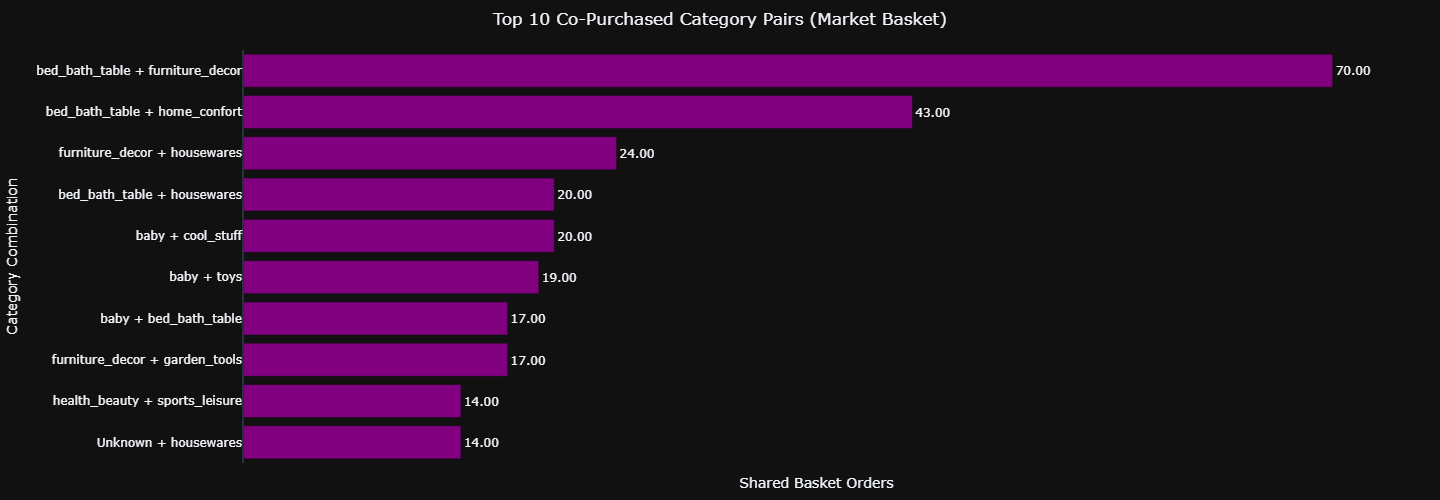

In [66]:
fig9 = px.bar(top_pairs, x='order_id', y='Pair', orientation='h',color='order_id',color_continuous_scale='Magma',title='Top 10 Co-Purchased Category Pairs (Market Basket)',
               labels={'order_id': 'Shared Basket Orders', 'Pair': 'Category Combination'},text='order_id')
fig9.update_traces(texttemplate='%{text:.2f}',textposition='outside',marker_color='purple')
fig9.update_layout(yaxis=dict(autorange="reversed"))
fig9.update_layout(height=500, width=1200,title_x=0.5,margin=dict(l=50, r=50, t=50, b=30),template='plotly_dark',coloraxis_showscale=False)
fig9.update_xaxes(showgrid=False,showticklabels=False)
fig9.show()
pio.write_json(fig9, "Co_products.json")